# Proyek Analisis Data: E-Commerce Public Dataset
- **Nama:** Noval Zachri Al Zamzami
- **Email:** novalzchri@gmail.com
- **ID Dicoding:** CDCC358D6Y2704

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- Pertanyaan 1 : Bagaimana tren total nilai pembayaran (payment value) per bulan selama periode 2016–2018, serta kategori produk apa yang memberikan kontribusi pendapatan tertinggi dalam periode tersebut?
- Pertanyaan 2 : Bagaimana segmentasi pelanggan berdasarkan Recency, Frequency, dan Monetary (RFM) selama periode 2016–2018, serta bagaimana kontribusi masing-masing segmen terhadap total pendapatan?

## Import Semua Packages/Library yang Digunakan

In [49]:
# 1. Library utama untuk manipulasi dan pengolahan data
import pandas as pd

# 2. Library utama untuk pembuatan visualisasi
import matplotlib.pyplot as plt
import seaborn as sns

# 3. Library tambahan untuk menjaga kerapian output notebook
import warnings

## Penjelasan singkat fungsinya:

1. pandas: Digunakan untuk membaca, mengolah, dan memanipulasi data dalam bentuk tabel (DataFrame).

2. matplotlib & seaborn: Digunakan untuk membuat visualisasi data seperti grafik dan plot agar lebih mudah dipahami.

3. warnings: Murni untuk estetika agar notebook kamu tetap bersih dan enak dibaca saat di-ulas (review).


## Data Wrangling

### Gathering Data

#### Load df ...

In [50]:
# --- TAHAP 1: DATA GATHERING ---

# 1. Menyimpan base URL dataset dari GitHub
# Base URL digunakan agar pemanggilan file CSV menjadi lebih ringkas
base_url = "https://raw.githubusercontent.com/nopal-upel/Dataset-Fundamental-Analisis-Data/main/"

# 2. Membaca masing-masing file CSV dan menyimpannya ke dalam DataFrame
# Setiap dataset merepresentasikan informasi yang berbeda (orders, customers, payments, dll)
orders = pd.read_csv(base_url + "orders_dataset.csv")
payments = pd.read_csv(base_url + "order_payments_dataset.csv")
customers = pd.read_csv(base_url + "customers_dataset.csv")
order_items = pd.read_csv(base_url + "order_items_dataset.csv")
products = pd.read_csv(base_url + "products_dataset.csv")

# 3. Menampilkan 5 baris pertama dari dataset orders
# Digunakan untuk melihat struktur awal data secara cepat
print("--- 5 Baris Pertama Dataset Orders ---")
display(orders.head())

--- 5 Baris Pertama Dataset Orders ---


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


**Insight:**
- Dataset berhasil dimuat dengan baik dari repository GitHub ke dalam DataFrame menggunakan fungsi `read_csv()` dari library pandas.
- Berdasarkan tampilan 5 baris pertama, terlihat bahwa struktur data sudah tersusun dengan rapi dalam format tabular, di mana setiap kolom merepresentasikan atribut tertentu seperti `order_id`, `customer_id`, `order_status`, serta informasi waktu terkait proses pemesanan dan pengiriman.
- Selain itu, tidak ditemukan adanya kesalahan format seperti kolom yang menyatu atau data yang tidak terbaca dengan benar. Hal ini menunjukkan bahwa proses pengambilan data berjalan dengan baik.
- Namun, dapat diamati bahwa beberapa kolom waktu masih berbentuk string (object), sehingga perlu dilakukan konversi ke tipe data datetime pada tahap selanjutnya agar dapat digunakan dalam analisis berbasis waktu.

Secara keseluruhan, dataset sudah siap untuk dilakukan proses pemeriksaan kualitas data pada tahap berikutnya.

### Assessing Data

#### Identifying ... problem

In [51]:
print("=== INFO DATA ORDERS ===")
orders.info()

print("\n=== MISSING VALUES ===")
print(orders.isnull().sum())

print("\n=== DUPLICATE DATA ===")
print(orders.duplicated().sum())

print("\n=== DESCRIPTIVE STATISTICS ===")
display(orders.describe())

=== INFO DATA ORDERS ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(8)
memory usage: 6.1+ MB

=== MISSING VALUES ===
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
count,99441,99441,99441,99441,99281,97658,96476,99441
unique,99441,99441,8,98875,90733,81018,95664,459
top,66dea50a8b16d9b4dee7af250b4be1a5,edb027a75a1449115f6b43211ae02a24,delivered,2018-08-02 12:06:07,2018-02-27 04:31:10,2018-05-09 15:48:00,2018-05-14 20:02:44,2017-12-20 00:00:00
freq,1,1,96478,3,9,47,3,522


**Steps to Take:**
- Cek struktur data
menggunakan orders.info() untuk melihat jumlah baris, jumlah kolom, nama kolom, tipe data, dan jumlah data non-null.
Dari sini bisa tahu apakah ada kolom yang tipe datanya belum sesuai, misalnya tanggal masih bertipe object padahal seharusnya datetime.
- Identifikasi missing values
memeriksa apakah terdapat nilai kosong pada setiap kolom. Jika ada missing value, tentukan tindakan yang sesuai, misalnya menghapus data kosong atau mengisinya dengan nilai tertentu sesuai kebutuhan analisis.
- Cek data duplikat
memeriksa apakah ada baris data yang terduplikasi. Jika ditemukan data duplikat, data tersebut perlu ditinjau dan biasanya dihapus agar hasil analisis tidak bias.
- Melihat statistik deskriptif
mengamati ringkasan statistik dari kolom numerik, seperti nilai rata-rata, minimum, maksimum, median, dan standar deviasi. Tahap ini membantu melihat pola awal data serta mendeteksi kemungkinan nilai yang tidak wajar.
- Menentukan langkah pembersihan data selanjutnya
nerdasarkan hasil pengecekan sebelumnya, tentukan apakah dataset perlu dibersihkan, seperti mengubah tipe data, menangani missing value, menghapus duplikat, atau mengecek outlier.
Secara keseluruhan, tahap ini bertujuan untuk memahami kondisi awal data orders sebelum dilakukan analisis lebih lanjut.

**Insight:**
- Hasil proses assessing menunjukkan bahwa terdapat 9 kolom yang terdapat pada dataset retail sales, beberapa di antaranya merupakan variabel yang dapat digunakan untuk menarik kesimpulan dan menjawab pertanyaan bisnis yang sudah ditentukan.
- Pada data yang digunakan terdapat beberapa kolom fitur yang mengalami kekosongan data, maka dari itu diperlukan adanya tahapan pembersihan atau pengisian data agar proses ekstraksi insight dalam berjalan dengan baik.
- Berdasarkan analisis statistik data numerik pada data yang digunakan, terdapat beberapa nilai yang tidak masuk akal atau irasional apabila dilihat dari nama variabelnya, seperti pada contoh kolom **Age** dengan data yang terdeteksi terdiri dari negative values yaitu -10 dan maximal value sebesar 227 tahun.

### Cleaning Data

#### Fixing ... problem

In [52]:
# --- TAHAP 3: DATA CLEANING ---

# 1. Membuat salinan data orders agar data asli tetap aman
orders_cleaned = orders.copy()

# 2. Mengubah kolom waktu dari object menjadi datetime
date_columns = [
    'order_purchase_timestamp',
    'order_approved_at',
    'order_delivered_carrier_date',
    'order_delivered_customer_date',
    'order_estimated_delivery_date'
]

for col in date_columns:
    orders_cleaned[col] = pd.to_datetime(orders_cleaned[col])

print("Tipe data setelah konversi:")
orders_cleaned.info()

Tipe data setelah konversi:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   order_id                       99441 non-null  object        
 1   customer_id                    99441 non-null  object        
 2   order_status                   99441 non-null  object        
 3   order_purchase_timestamp       99441 non-null  datetime64[ns]
 4   order_approved_at              99281 non-null  datetime64[ns]
 5   order_delivered_carrier_date   97658 non-null  datetime64[ns]
 6   order_delivered_customer_date  96476 non-null  datetime64[ns]
 7   order_estimated_delivery_date  99441 non-null  datetime64[ns]
dtypes: datetime64[ns](5), object(3)
memory usage: 6.1+ MB


In [53]:
# 3. Mengecek dan menghapus data duplikat
orders_cleaned = orders_cleaned.drop_duplicates()

print("Jumlah duplikat setelah cleaning:", orders_cleaned.duplicated().sum())

Jumlah duplikat setelah cleaning: 0


In [54]:
# 4. Menangani missing value secara selektif
# Kolom order_purchase_timestamp penting untuk analisis waktu, sehingga harus dipastikan tidak kosong
orders_cleaned = orders_cleaned.dropna(subset=['order_purchase_timestamp'])

print("Missing values setelah cleaning:")
print(orders_cleaned.isna().sum())

Missing values setelah cleaning:
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64


In [55]:
# 5. Menampilkan data setelah cleaning
print("--- Data Orders Setelah Cleaning ---")
display(orders_cleaned.head())

print("Jumlah baris akhir:", len(orders_cleaned))

# Update DataFrame orders
orders = orders_cleaned
print("DataFrame 'orders' telah diperbarui dengan data yang sudah dibersihkan.")

--- Data Orders Setelah Cleaning ---


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26


Jumlah baris akhir: 99441
DataFrame 'orders' telah diperbarui dengan data yang sudah dibersihkan.


**Insight:**
- Pada tahap cleaning, data tidak dibersihkan dengan cara menghapus seluruh missing values karena beberapa nilai kosong pada kolom pengiriman dapat merepresentasikan pesanan yang belum selesai diproses.
- Langkah utama yang dilakukan adalah mengubah kolom waktu menjadi tipe datetime agar dapat digunakan dalam analisis berbasis waktu. Selain itu, data duplikat juga diperiksa dan dihapus apabila ditemukan.
- Dengan proses ini, dataset orders menjadi lebih siap digunakan untuk analisis tren transaksi dan analisis lanjutan seperti segmentasi pelanggan.

## Exploratory Data Analysis (EDA)

### Explore ...

In [56]:
# 1. Membuat dataset gabungan untuk analisis revenue dan kategori produk
df_eda = orders.merge(order_items, on='order_id')
df_eda = df_eda.merge(products, on='product_id')
df_eda = df_eda.merge(payments, on='order_id')

# Menyimpan data gabungan untuk dashboard
df_eda.to_csv("main_data.csv", index=False)

print("--- 5 Baris Pertama Data Gabungan ---")
display(df_eda.head())

# 2. Membuat kolom bulan transaksi
df_eda['order_month'] = df_eda['order_purchase_timestamp'].dt.to_period('M').astype(str)

# 3. Ringkasan statistik payment_value
print("\n--- Ringkasan Statistik Payment Value ---")
display(df_eda['payment_value'].describe())

# 4. Tren total payment per bulan
monthly_revenue = df_eda.groupby('order_month')['payment_value'].sum().reset_index()

print("\n--- Total Payment per Bulan ---")
display(monthly_revenue.head())

# 5. Kategori produk dengan payment terbesar
category_revenue = (
    df_eda.groupby('product_category_name')['payment_value']
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

print("\n--- Top 10 Kategori Produk Berdasarkan Payment ---")
display(category_revenue.head(10))

--- 5 Baris Pertama Data Gabungan ---


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,order_item_id,product_id,...,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm,payment_sequential,payment_type,payment_installments,payment_value
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,1,87285b34884572647811a353c7ac498a,...,268.0,4.0,500.0,19.0,8.0,13.0,1,credit_card,1,18.12
1,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,1,87285b34884572647811a353c7ac498a,...,268.0,4.0,500.0,19.0,8.0,13.0,3,voucher,1,2.00
2,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,1,87285b34884572647811a353c7ac498a,...,268.0,4.0,500.0,19.0,8.0,13.0,2,voucher,1,18.59
3,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,1,595fac2a385ac33a80bd5114aec74eb8,...,178.0,1.0,400.0,19.0,13.0,19.0,1,boleto,1,141.46
4,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,1,aa4383b373c6aca5d8797843e5594415,...,232.0,1.0,420.0,24.0,19.0,21.0,1,credit_card,3,179.12



--- Ringkasan Statistik Payment Value ---


,payment_value
count,117601.000000
mean,172.686752
std,267.592290
min,0.000000
25%,60.870000
50%,108.210000
75%,189.260000
max,13664.080000



--- Total Payment per Bulan ---


,order_month,payment_value
0,2016-09,347.52
1,2016-10,73914.58
2,2016-12,19.62
3,2017-01,187779.41
4,2017-02,344134.79



--- Top 10 Kategori Produk Berdasarkan Payment ---


,product_category_name,payment_value
0,cama_mesa_banho,1712553.67
1,beleza_saude,1657373.12
2,informatica_acessorios,1585330.45
3,moveis_decoracao,1430176.39
4,relogios_presentes,1429216.68
5,esporte_lazer,1392127.56
6,utilidades_domesticas,1094758.13
7,automotivo,852294.33
8,ferramentas_jardim,838280.75
9,cool_stuff,779698.00


**Insight:**
- Berdasarkan hasil eksplorasi, data transaksi berhasil digabungkan dari beberapa tabel utama seperti orders, order_items, products, dan payments.
- Kolom `payment_value` digunakan sebagai metrik utama untuk melihat pola pendapatan. Selain itu, kolom `order_purchase_timestamp` digunakan untuk membentuk agregasi bulanan sehingga tren pendapatan dapat dianalisis dari waktu ke waktu.
- Hasil grouping berdasarkan kategori produk menunjukkan adanya perbedaan kontribusi pendapatan antar kategori. Kategori dengan total payment tertinggi dapat menjadi fokus utama dalam strategi penjualan dan pemasaran.

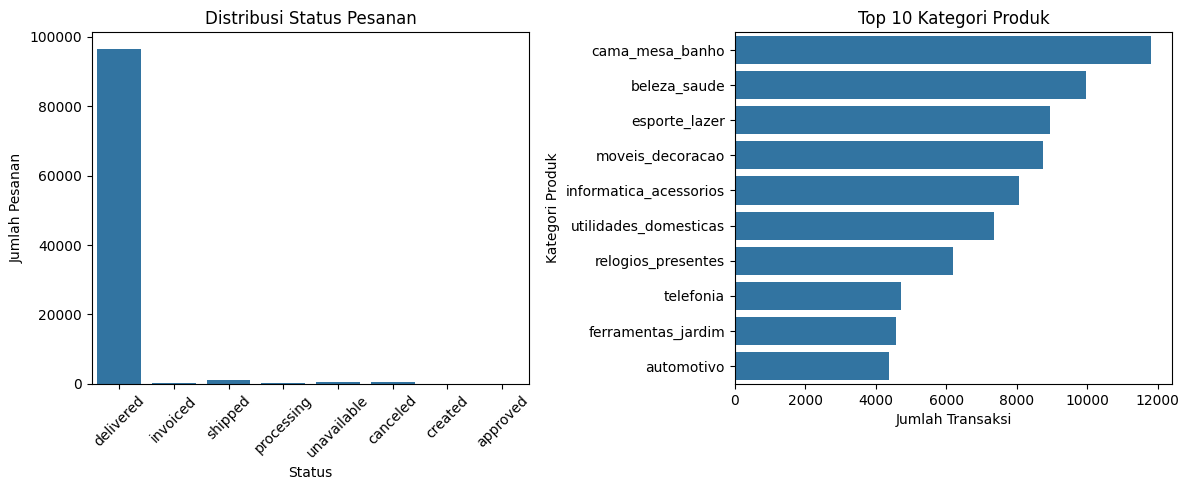

In [57]:
plt.figure(figsize=(12, 5))

#Visualisasi Distribusi Status Pesanan
plt.subplot(1, 2, 1)
sns.countplot(data=orders, x='order_status')
plt.title("Distribusi Status Pesanan")
plt.xlabel("Status")
plt.ylabel("Jumlah Pesanan")
plt.xticks(rotation=45)

#Visualisai Distribusi Kategori Produk
top_category = df_eda['product_category_name'].value_counts().head(10)

plt.subplot(1, 2, 2)
sns.barplot(x=top_category.values, y=top_category.index)
plt.title("Top 10 Kategori Produk")
plt.xlabel("Jumlah Transaksi")
plt.ylabel("Kategori Produk")

plt.tight_layout()
plt.show()

**Insight:**
- Berdasarkan visualisasi distribusi status pesanan, terlihat bahwa sebagian besar transaksi memiliki status "delivered". Hal ini menunjukkan bahwa mayoritas pesanan berhasil diproses dan sampai ke pelanggan.
- Di sisi lain, terdapat beberapa status lain seperti "canceled" dan "unavailable", meskipun jumlahnya relatif kecil. Hal ini dapat menjadi bahan evaluasi dalam meningkatkan kualitas layanan dan proses operasional.
- Untuk distribusi kategori produk, terlihat bahwa beberapa kategori memiliki jumlah transaksi yang jauh lebih tinggi dibandingkan kategori lainnya. Hal ini menunjukkan adanya preferensi pelanggan terhadap jenis produk tertentu.
- Kategori dengan jumlah transaksi tertinggi dapat menjadi fokus utama dalam strategi pemasaran, pengelolaan stok, serta pengembangan bisnis ke depannya.

## Visualization & Explanatory Analysis

### Pertanyaan 1:

In [58]:
# 1. Menghitung total pendapatan per bulan (Pertanyaan 1)
df_eda['order_month'] = df_eda['order_purchase_timestamp'].dt.to_period('M').astype(str)

monthly_revenue = df_eda.groupby('order_month')['payment_value'].sum().reset_index()

print("\n--- Total Pendapatan per Bulan ---")
display(monthly_revenue.head())


# 2. Menghitung pendapatan berdasarkan kategori produk
category_revenue = (
    df_eda.groupby('product_category_name')['payment_value']
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

print("\n--- Top Kategori Produk ---")
display(category_revenue.head())


--- Total Pendapatan per Bulan ---


,order_month,payment_value
0,2016-09,347.52
1,2016-10,73914.58
2,2016-12,19.62
3,2017-01,187779.41
4,2017-02,344134.79



--- Top Kategori Produk ---


,product_category_name,payment_value
0,cama_mesa_banho,1712553.67
1,beleza_saude,1657373.12
2,informatica_acessorios,1585330.45
3,moveis_decoracao,1430176.39
4,relogios_presentes,1429216.68


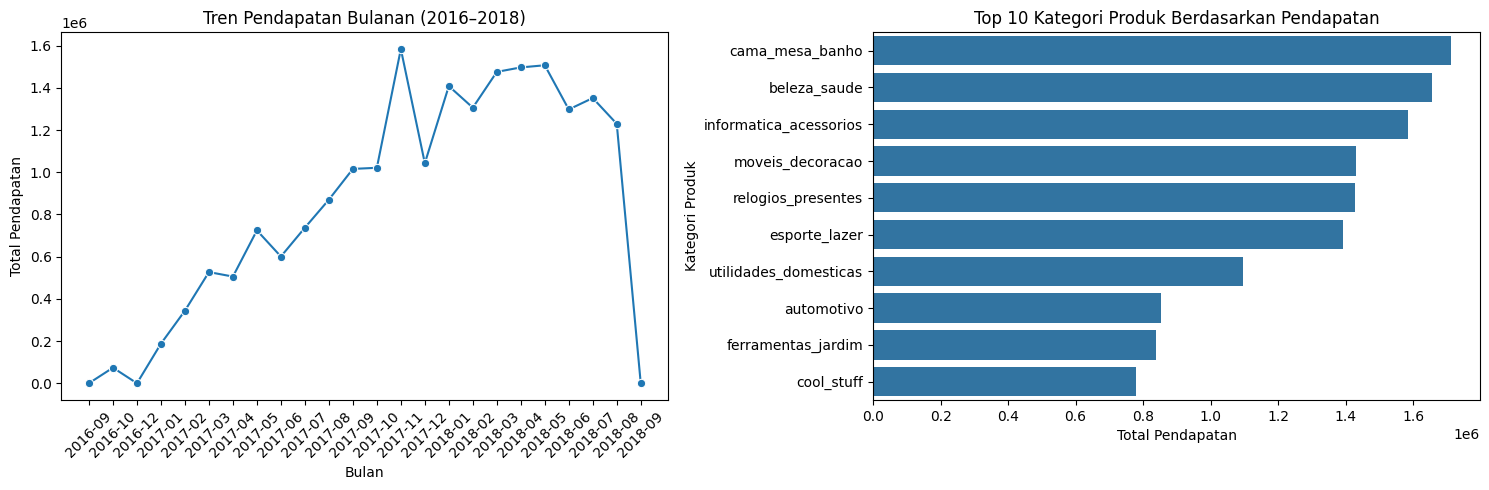

In [59]:
plt.figure(figsize=(15,5))

# Visualisasi 1: Tren Pendapatan Bulanan
plt.subplot(1, 2, 1)
sns.lineplot(data=monthly_revenue, x='order_month', y='payment_value', marker='o')
plt.title("Tren Pendapatan Bulanan (2016–2018)")
plt.xlabel("Bulan")
plt.ylabel("Total Pendapatan")
plt.xticks(rotation=45)

# Visualisasi 2: Top Kategori Produk
plt.subplot(1, 2, 2)
sns.barplot(
    data=category_revenue.head(10),
    x='payment_value',
    y='product_category_name'
)
plt.title("Top 10 Kategori Produk Berdasarkan Pendapatan")
plt.xlabel("Total Pendapatan")
plt.ylabel("Kategori Produk")

plt.tight_layout()
plt.show()

### Pertanyaan 2:

In [60]:
# 1. Menggabungkan dataset untuk analisis RFM
rfm_df = orders.merge(payments, on='order_id')
rfm_df = rfm_df.merge(customers, on='customer_id')

# 2. Menentukan snapshot date
snapshot_date = rfm_df['order_purchase_timestamp'].max()

# 3. Menghitung RFM
rfm = rfm_df.groupby('customer_id').agg({
    'order_purchase_timestamp': lambda x: (snapshot_date - x.max()).days,
    'order_id': 'count',
    'payment_value': 'sum'
}).reset_index()

rfm.columns = ['customer_id', 'recency', 'frequency', 'monetary']

rfm = rfm.dropna()

print("\n--- Data RFM ---")
display(rfm.head())


--- Data RFM ---


,customer_id,recency,frequency,monetary
0,00012a2ce6f8dcda20d059ce98491703,337,1,114.74
1,000161a058600d5901f007fab4c27140,458,1,67.41
2,0001fd6190edaaf884bcaf3d49edf079,596,1,195.42
3,0002414f95344307404f0ace7a26f1d5,427,1,179.35
4,000379cdec625522490c315e70c7a9fb,198,1,107.01


In [61]:
# 4. Segmentasi pelanggan berdasarkan Monetary (lebih efisien)

# Menghitung threshold quantile terlebih dahulu (biar tidak dihitung berulang)
q25 = rfm['monetary'].quantile(0.25)
q75 = rfm['monetary'].quantile(0.75)

# Fungsi untuk menentukan segmentasi
def segment_customer(m):
    if m >= q75:
        return "High Value"
    elif m >= q25:
        return "Medium Value"
    else:
        return "Low Value"

# Menerapkan segmentasi ke dataset RFM
rfm['segment'] = rfm['monetary'].apply(segment_customer)

# Menampilkan distribusi segmentasi
print("\n--- Distribusi Segment Pelanggan ---")
print(rfm['segment'].value_counts())


--- Distribusi Segment Pelanggan ---
segment
Medium Value    49726
High Value      24862
Low Value       24852
Name: count, dtype: int64


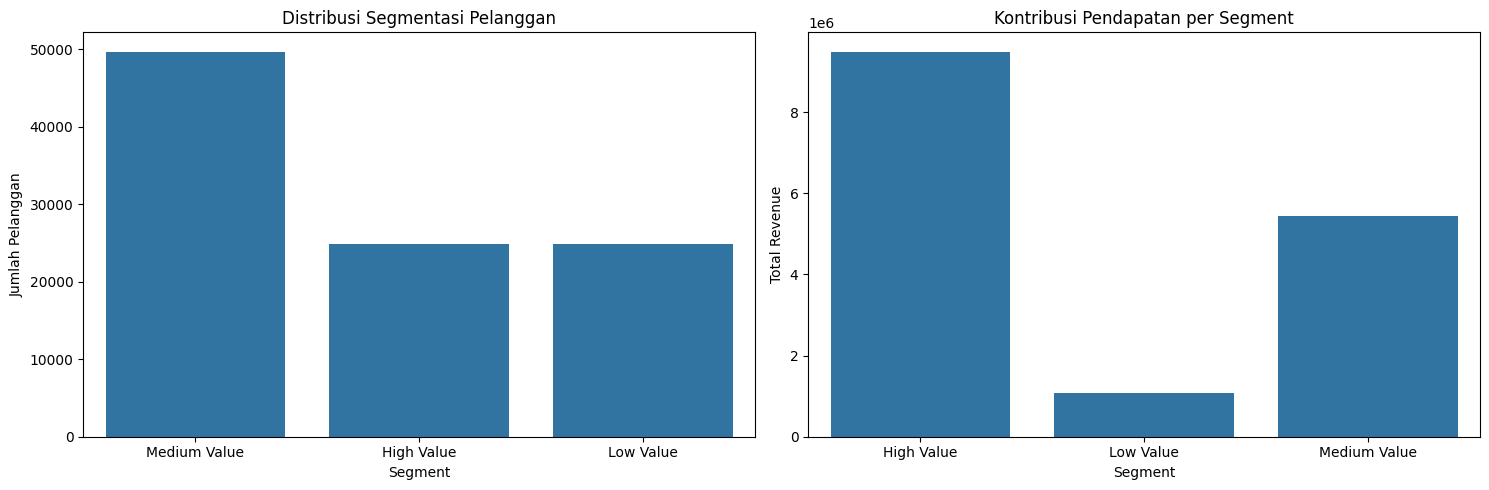

In [62]:
plt.figure(figsize=(15,5))

# Visualisasi 1: Distribusi pelanggan
plt.subplot(1, 2, 1)
sns.countplot(data=rfm, x='segment')
plt.title("Distribusi Segmentasi Pelanggan")
plt.xlabel("Segment")
plt.ylabel("Jumlah Pelanggan")

# Visualisasi 2: Kontribusi revenue
segment_revenue = rfm.groupby('segment')['monetary'].sum().reset_index()

plt.subplot(1, 2, 2)
sns.barplot(data=segment_revenue, x='segment', y='monetary')
plt.title("Kontribusi Pendapatan per Segment")
plt.xlabel("Segment")
plt.ylabel("Total Revenue")

plt.tight_layout()
plt.show()

### Insight pertanyaan 1

- Terlihat bahwa pendapatan mengalami fluktuasi dari waktu ke waktu dengan kecenderungan meningkat pada periode tertentu.
- Selain itu, beberapa kategori produk memberikan kontribusi pendapatan yang jauh lebih besar dibandingkan kategori lainnya, menunjukkan adanya produk unggulan dalam bisnis.

### Insight pertanyaan 2

- Pelanggan didominasi oleh segmen Low dan Medium Value.
- Namun, segmen High Value memberikan kontribusi pendapatan terbesar, sehingga pelanggan dalam segmen ini sangat penting untuk dipertahankan.

## Analisis Lanjutan (Opsional)

In [63]:
print("=== MELAKUKAN RFM ANALYSIS ===")

# 1. Menggabungkan dataset yang dibutuhkan
rfm_df = orders.merge(payments, on='order_id')

# 2. Menentukan snapshot date (tanggal terakhir transaksi)
snapshot_date = rfm_df['order_purchase_timestamp'].max()

# 3. Menghitung Recency, Frequency, Monetary
rfm = rfm_df.groupby('customer_id').agg({
    'order_purchase_timestamp': lambda x: (snapshot_date - x.max()).days,  # Recency
    'order_id': 'count',  # Frequency
    'payment_value': 'sum'  # Monetary
}).reset_index()

rfm.columns = ['customer_id', 'recency', 'frequency', 'monetary']

# Membersihkan data kosong
rfm = rfm.dropna()

print("\n--- Data RFM (5 Baris Pertama) ---")
display(rfm.head())

# 4. Menentukan threshold segmentasi berdasarkan quantile
q25 = rfm['monetary'].quantile(0.25)
q75 = rfm['monetary'].quantile(0.75)

# 5. Membuat fungsi segmentasi pelanggan
def segment_customer(m):
    if m >= q75:
        return "High Value"
    elif m >= q25:
        return "Medium Value"
    else:
        return "Low Value"

# 6. Menerapkan segmentasi
rfm['segment'] = rfm['monetary'].apply(segment_customer)

print("\n--- Distribusi Segment Pelanggan ---")
print(rfm['segment'].value_counts())

=== MELAKUKAN RFM ANALYSIS ===

--- Data RFM (5 Baris Pertama) ---


,customer_id,recency,frequency,monetary
0,00012a2ce6f8dcda20d059ce98491703,337,1,114.74
1,000161a058600d5901f007fab4c27140,458,1,67.41
2,0001fd6190edaaf884bcaf3d49edf079,596,1,195.42
3,0002414f95344307404f0ace7a26f1d5,427,1,179.35
4,000379cdec625522490c315e70c7a9fb,198,1,107.01



--- Distribusi Segment Pelanggan ---
segment
Medium Value    49726
High Value      24862
Low Value       24852
Name: count, dtype: int64


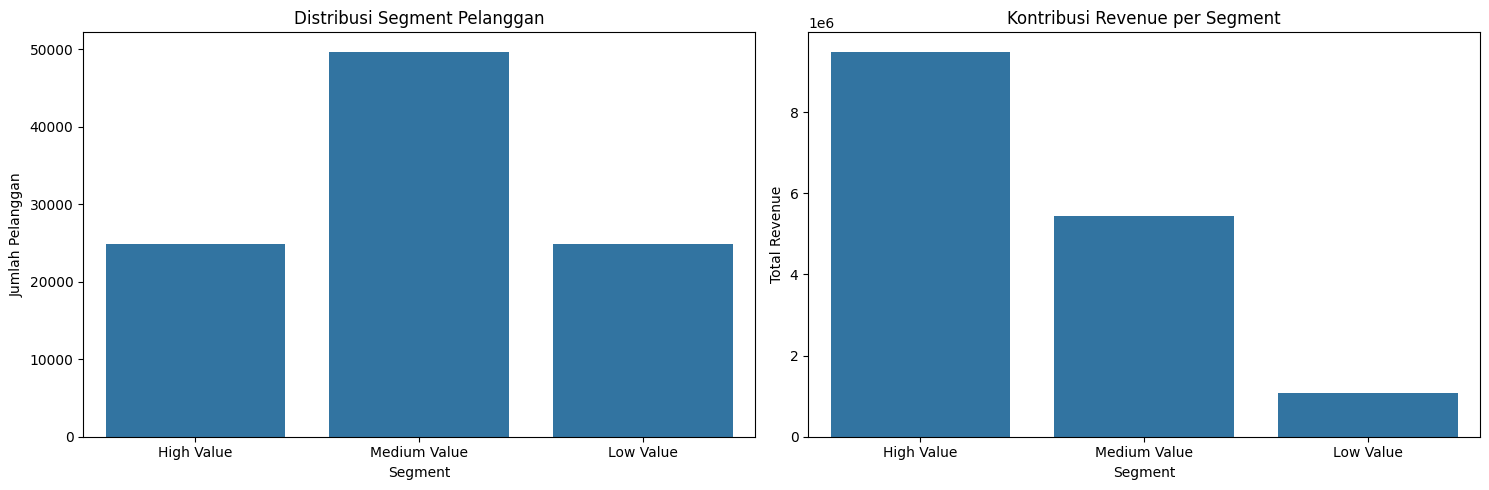

In [64]:
plt.figure(figsize=(15,5))

# Visualisasi 1: Distribusi Segment
plt.subplot(1,2,1)
sns.countplot(data=rfm, x='segment', order=['High Value', 'Medium Value', 'Low Value'])
plt.title("Distribusi Segment Pelanggan")
plt.xlabel("Segment")
plt.ylabel("Jumlah Pelanggan")

# Visualisasi 2: Kontribusi Revenue per Segment
segment_revenue = rfm.groupby('segment')['monetary'].sum().reset_index()

plt.subplot(1,2,2)
sns.barplot(data=segment_revenue, x='segment', y='monetary', order=['High Value', 'Medium Value', 'Low Value'])
plt.title("Kontribusi Revenue per Segment")
plt.xlabel("Segment")
plt.ylabel("Total Revenue")

plt.tight_layout()
plt.show()

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Tren Pendapatan & Kategori Produk
Berdasarkan visualisasi, total nilai pembayaran (payment value) per bulan selama periode 2016–2018 menunjukkan pola fluktuatif dengan kecenderungan meningkat di periode tertentu.
Hal ini mengindikasikan adanya momen tertentu (seperti promo atau musim belanja) yang memengaruhi peningkatan transaksi.
Selain itu, terdapat beberapa kategori produk yang secara konsisten memberikan kontribusi pendapatan tertinggi, yang menunjukkan bahwa kategori tersebut merupakan driver utama revenue perusahaan.
Segmentasi Pelanggan (RFM)
Hasil analisis RFM menunjukkan bahwa pelanggan dapat dibagi menjadi tiga segmen utama:
High Value → pelanggan dengan kontribusi revenue terbesar
Medium Value → pelanggan dengan potensi untuk ditingkatkan
Low Value → pelanggan dengan kontribusi rendah
Visualisasi menunjukkan bahwa meskipun jumlah pelanggan di segmen tertentu lebih banyak, kontribusi revenue terbesar biasanya berasal dari segmen High Value.
Hal ini menegaskan bahwa tidak semua pelanggan memiliki nilai yang sama terhadap bisnis.
- **Conclusion pertanyaan 2:** Segmentasi Pelanggan (RFM)
Hasil analisis RFM menunjukkan bahwa pelanggan dapat dibagi menjadi tiga segmen utama:
High Value → pelanggan dengan kontribusi revenue terbesar
Medium Value → pelanggan dengan potensi untuk ditingkatkan
Low Value → pelanggan dengan kontribusi rendah
Visualisasi menunjukkan bahwa meskipun jumlah pelanggan di segmen tertentu lebih banyak, kontribusi revenue terbesar biasanya berasal dari segmen High Value.
Hal ini menegaskan bahwa tidak semua pelanggan memiliki nilai yang sama terhadap bisnis.

**Rekomendasi Action Item:**
- Fokus Retensi Pelanggan High Value
Memberikan program loyalitas seperti: diskon eksklusif, early, access promo, membership premium. Tujuannya: menjaga pelanggan dengan kontribusi terbesar agar tidak churn
- Optimasi Kategori Produk Unggulan
Tingkatkan strategi marketing pada kategori dengan revenue tertinggi: promo bundling, iklan digital lebih agresi. Tujuannya: memaksimalkan revenue dari produk yang sudah terbukti laku
- Aktivasi Pelanggan Low Value
Gunakan strategi re-engagement seperti: email marketing, voucher diskon pertama/ulang. Tujuannya: meningkatkan frekuensi transaksi dari pelanggan pasif